# Studi Kasus Machine Learning: Prediksi Harga Rumah (House Price Prediction)
**Mata Kuliah / Kegiatan:** Kuliah Umum Introduction to Machine Learning (Ibu Taniza Tajudin - UiTM Malaysia)  
**Pendekatan:** Supervised Learning — Regression  

---
## Step 1: Data Collection (Pengumpulan Data)
Pada tahap pertama ini, kita mengumpulkan data properti rumah yang merepresentasikan kondisi data mentah (*raw data*) di dunia nyata. Sesuai dengan pemaparan materi kuliah umum, dataset ini memiliki 3 fitur masukan (*input features* / kolom atribut) dan 1 target keluaran (*output label*):

**Size_sqft:** Ukuran luas bangunan rumah ( dalam satuan *square feet*).

**Bedrooms:** Jumlah kamar tidur.

**Location:** Lokasi kota rumah berada (`City A` = Pusat Kota Besar, `City B` = Pinggiran Kota, `City C` = Area Pedesaan).

**Price_USD:** Harga rumah dalam satuan USD (sebagai target yang akan diprediksi).

Dataset mentah ini sengaja memuat permasalahan data dunia nyata (seperti *missing values* / nilai kosong, data duplikat, dan *outlier* / nilai ekstrem) yang nantinya akan dibersihkan pada tahap *Data Preprocessing*.

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)

jumlah_data = 150
size_sqft = np.random.randint(800, 3500, size=jumlah_data).astype(float)
bedrooms = np.random.randint(1, 6, size=jumlah_data).astype(float)
locations = np.random.choice(['City A', 'City B', 'City C'], size=jumlah_data, p=[0.4, 0.35, 0.25])

bonus_lokasi = np.where(locations == 'City A', 80000,
               np.where(locations == 'City B', 40000, 10000))

price_usd = (size_sqft * 120) + (bedrooms * 15000) + bonus_lokasi + np.random.normal(0, 12000, size=jumlah_data)
price_usd = np.round(price_usd, 2)

df_raw = pd.DataFrame({
    'Size_sqft': size_sqft,
    'Bedrooms': bedrooms,
    'Location': locations,
    'Price_USD': price_usd
})

df_raw.loc[[5, 18, 42, 88, 110], 'Size_sqft'] = np.nan
df_raw.loc[[12, 65, 95], 'Bedrooms'] = np.nan

df_raw.loc[25, 'Price_USD'] = 9500000.00
df_raw.loc[70, 'Size_sqft'] = 25000.00

baris_duplikat = df_raw.iloc[[0, 1, 2, 3]].copy()
df_raw = pd.concat([df_raw, baris_duplikat], ignore_index=True)

df_raw.to_csv('raw_house_data.csv', index=False)
print("File 'raw_house_data.csv' berhasil dibuat dan disimpan")
print(f"Total Baris Data (Instances/Records): {df_raw.shape[0]} baris")
print(f"Total Kolom (Features + Target): {df_raw.shape[1]} kolom\n")

print("--- TAMPILAN 10 BARIS PERTAMA DATA MENTAH (RAW DATA) ---")
display(df_raw.head(10))

File 'raw_house_data.csv' berhasil dibuat dan disimpan
Total Baris Data (Instances/Records): 154 baris
Total Kolom (Features + Target): 4 kolom

--- TAMPILAN 10 BARIS PERTAMA DATA MENTAH (RAW DATA) ---


,Size_sqft,Bedrooms,Location,Price_USD
0,1660.0,3.0,City C,260105.69
1,2094.0,2.0,City B,302950.57
2,1930.0,4.0,City C,303765.91
3,1895.0,1.0,City A,335252.50
4,2438.0,1.0,City B,356733.74
5,NaN,1.0,City B,397946.03
6,1266.0,1.0,City C,166568.62
7,2038.0,3.0,City A,379047.13
8,1130.0,1.0,City A,238194.23
9,2282.0,4.0,City A,386790.10


---
## Step 2: Data Preprocessing (Pra-pemrosesan & Pembersihan Data)
Sesuai dengan materi yang disampaikan oleh Ibu Taniza Tajudin, kualitas prediksi dari algoritma *Machine Learning* sangat bergantung pada kualitas data masukan (*good quality data produces accurate prediction*). Oleh karena itu, sebelum melatih model, kita melakukan tahapan **Data Preprocessing** berikut:
1. **Inspeksi Data Mentah:** Mengecek jumlah nilai yang hilang (*missing values*), data ganda (*duplicates*), dan nilai ekstrem (*outliers*).
2. **Penghapusan Duplikat:** Menghapus baris data yang terduplikasi.
3. **Imputasi *Missing Values*:** Mengisi nilai kosong (`NaN`) pada kolom `Size_sqft` dan `Bedrooms` menggunakan nilai *median* (nilai tengah).
4. **Pembersihan *Outliers*:** Memfilter data anomali yang berada di luar batas kewajaran.
5. **Konversi Tipe Data (*Encoding*):** Mengubah data kategorikal teks pada kolom `Location` menjadi representasi numerik (`City C` = 1, `City B` = 2, `City A` = 3).
6. **Normalisasi (*Min-Max Scaling*):** Mentransformasi skala fitur ke rentang 0 hingga 1 untuk melihat bentuk data yang siap dikomputasi.

=== 1. KONDISI AWAL DATA MENTAH (SEBELUM PREPROCESSING) ===
Total Baris Awal         : 154 baris
Jumlah Baris Duplikat    : 4 baris
Jumlah Missing Values (NaN) per Kolom:
Size_sqft    5
Bedrooms     3
Location     0
Price_USD    0
dtype: int64
-------------------------------------------------------

=== 2. KONDISI DATA SETELAH PREPROCESSING ===
Total Baris Bersih       : 148 baris (4 duplikat & 2 outlier telah dihapus)
Total Missing Values     : 0 (Semua NaN sudah diisi dengan Median)
File 'cleaned_house_data.csv' berhasil disimpan

--- TAMPILAN 10 BARIS PERTAMA DATA BERSIH (PERHATIKAN BARIS INDEKS 5 SUDAH TIDAK NaN) ---


,Size_sqft,Bedrooms,Location,Location_Encoded,Price_USD
0,1660.0,3.0,City C,1,260105.69
1,2094.0,2.0,City B,2,302950.57
2,1930.0,4.0,City C,1,303765.91
3,1895.0,1.0,City A,3,335252.50
4,2438.0,1.0,City B,2,356733.74
5,2278.0,1.0,City B,2,397946.03
6,1266.0,1.0,City C,1,166568.62
7,2038.0,3.0,City A,3,379047.13
8,1130.0,1.0,City A,3,238194.23
9,2282.0,4.0,City A,3,386790.10



--- CONTOH 5 BARIS HASIL NORMALISASI (RENTANG 0 HINGGA 1) ---


,Size_Normalized,Bedrooms_Normalized,Location_Normalized,Price_Normalized
0,0.3138,0.50,0.0,0.2575
1,0.4761,0.25,0.5,0.3571
2,0.4147,0.75,0.0,0.3590
3,0.4016,0.00,1.0,0.4321
4,0.6047,0.00,0.5,0.4820


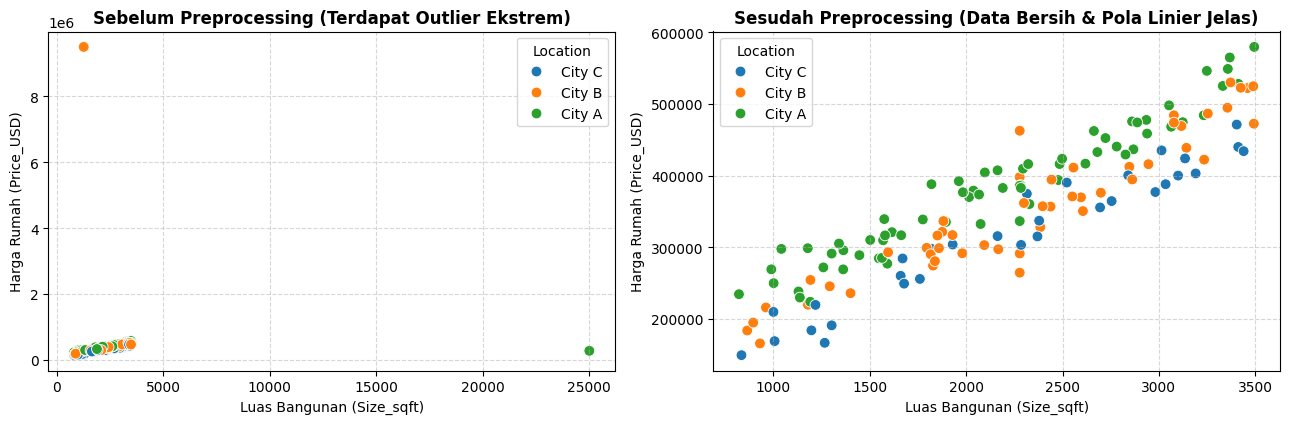

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
import os

if not os.path.exists('raw_house_data.csv'):
    np.random.seed(42)
    n = 150
    sz = np.random.randint(800, 3500, size=n).astype(float)
    bd = np.random.randint(1, 6, size=n).astype(float)
    loc = np.random.choice(['City A', 'City B', 'City C'], size=n, p=[0.4, 0.35, 0.25])
    b_loc = np.where(loc == 'City A', 80000, np.where(loc == 'City B', 40000, 10000))
    prc = np.round((sz * 120) + (bd * 15000) + b_loc + np.random.normal(0, 12000, size=n), 2)
    df_temp = pd.DataFrame({'Size_sqft': sz, 'Bedrooms': bd, 'Location': loc, 'Price_USD': prc})
    df_temp.loc[[5, 18, 42, 88, 110], 'Size_sqft'] = np.nan
    df_temp.loc[[12, 65, 95], 'Bedrooms'] = np.nan
    df_temp.loc[25, 'Price_USD'] = 9500000.00
    df_temp.loc[70, 'Size_sqft'] = 25000.00
    df_temp = pd.concat([df_temp, df_temp.iloc[[0, 1, 2, 3]].copy()], ignore_index=True)
    df_temp.to_csv('raw_house_data.csv', index=False)

df_raw = pd.read_csv('raw_house_data.csv')

print("=== 1. KONDISI AWAL DATA MENTAH (SEBELUM PREPROCESSING) ===")
print(f"Total Baris Awal         : {len(df_raw)} baris")
print(f"Jumlah Baris Duplikat    : {df_raw.duplicated().sum()} baris")
print("Jumlah Missing Values (NaN) per Kolom:")
print(df_raw.isnull().sum())
print("-" * 55)

df_clean = df_raw.copy()

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

median_size = df_clean['Size_sqft'].median()
median_bed = df_clean['Bedrooms'].median()
df_clean['Size_sqft'] = df_clean['Size_sqft'].fillna(median_size)
df_clean['Bedrooms'] = df_clean['Bedrooms'].fillna(median_bed)

jumlah_sebelum_outlier = len(df_clean)
df_clean = df_clean[(df_clean['Size_sqft'] < 10000) & (df_clean['Price_USD'] < 1500000)].reset_index(drop=True)
outlier_terbuang = jumlah_sebelum_outlier - len(df_clean)

mapping_lokasi = {'City C': 1, 'City B': 2, 'City A': 3}
df_clean['Location_Encoded'] = df_clean['Location'].map(mapping_lokasi)

df_clean = df_clean[['Size_sqft', 'Bedrooms', 'Location', 'Location_Encoded', 'Price_USD']]
df_clean.to_csv('cleaned_house_data.csv', index=False)

print("\n=== 2. KONDISI DATA SETELAH PREPROCESSING ===")
print(f"Total Baris Bersih       : {len(df_clean)} baris (4 duplikat & {outlier_terbuang} outlier telah dihapus)")
print(f"Total Missing Values     : {df_clean.isnull().sum().sum()} (Semua NaN sudah diisi dengan Median)")
print("File 'cleaned_house_data.csv' berhasil disimpan\n")

print("--- TAMPILAN 10 BARIS PERTAMA DATA BERSIH (PERHATIKAN BARIS INDEKS 5 SUDAH TIDAK NaN) ---")
display(df_clean.head(10))

scaler = MinMaxScaler()
df_normalized = pd.DataFrame(
    scaler.fit_transform(df_clean[['Size_sqft', 'Bedrooms', 'Location_Encoded', 'Price_USD']]),
    columns=['Size_Normalized', 'Bedrooms_Normalized', 'Location_Normalized', 'Price_Normalized']
)
print("\n--- CONTOH 5 BARIS HASIL NORMALISASI (RENTANG 0 HINGGA 1) ---")
display(df_normalized.head(5).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(data=df_raw, x='Size_sqft', y='Price_USD', hue='Location', ax=axes[0], s=60)
axes[0].set_title('Sebelum Preprocessing (Terdapat Outlier Ekstrem)', fontweight='bold')
axes[0].set_xlabel('Luas Bangunan (Size_sqft)')
axes[0].set_ylabel('Harga Rumah (Price_USD)')
axes[0].grid(True, linestyle='--', alpha=0.5)

sns.scatterplot(data=df_clean, x='Size_sqft', y='Price_USD', hue='Location', ax=axes[1], s=60)
axes[1].set_title('Sesudah Preprocessing (Data Bersih & Pola Linier Jelas)', fontweight='bold')
axes[1].set_xlabel('Luas Bangunan (Size_sqft)')
axes[1].set_ylabel('Harga Rumah (Price_USD)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## Step 3, 4, & 5: Split Data, Choose Model, & Train Model
Setelah data bersih melalui tahap *preprocessing*, kita melanjutkan ke tiga tahapan inti berikutnya sesuai alur kerja (*workflow*) Ibu Taniza Tajudin:

1. **Step 3 — Split Data (Pembagian Data Latih & Uji):**
   Membagi dataset bersih (`148 baris`) menjadi **80% Training Set** (`118 baris`) untuk melatih model mengenali pola umum (*generalization*), dan **20% Testing Set** (`30 baris`) sebagai *unseen data* untuk keperluan validasi/pengujian performa model.
2. **Step 4 — Choose Model (Pemilihan Algoritma Regresi):**
   Karena target prediksi berupa nilai numerik kontinu (`Price_USD`), kita memilih 3 algoritma *Supervised Learning — Regression* yang disebutkan pada materi kuliah umum:
   
   **Linear Regression**
   
   **Polynomial Regression (Degree 2)**
   
   **Support Vector Regression (SVR)**
3. **Step 5 — Train Model (Pelatihan Model):**
   Melatih ketiga algoritma menggunakan data latih (`X_train` dan `y_train`) agar model mempelajari hubungan matematis antara fitur masukan (`Size_sqft`, `Bedrooms`, `Location_Encoded`) dan target harga rumah (`Price_USD`).

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor

df_clean = pd.read_csv('cleaned_house_data.csv')

X = df_clean[['Size_sqft', 'Bedrooms', 'Location_Encoded']]
y = df_clean['Price_USD']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("=== HASIL STEP 3: PEMBAGIAN DATA (DATA SPLITTING 80:20) ===")
print(f"Total Data Bersih           : {len(df_clean)} baris (100%)")
print(f"Jumlah Data Latih (Training): {len(X_train)} baris (80%) -> Digunakan untuk melatih algoritma")
print(f"Jumlah Data Uji (Testing)   : {len(X_test)} baris (20%) -> Disimpan untuk menguji akurasi model")
print("-" * 65)

model_linear = LinearRegression()

model_poly = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

model_svr = TransformedTargetRegressor(
    regressor=make_pipeline(StandardScaler(), SVR(kernel='rbf', C=10.0, epsilon=0.05)),
    transformer=StandardScaler()
)

model_linear.fit(X_train, y_train)
model_poly.fit(X_train, y_train)
model_svr.fit(X_train, y_train)

print("\n=== HASIL STEP 4 & 5: PELATIHAN 3 MODEL REGRESI SELESAI ===")
print("1. Linear Regression berhasil mempelajari pola data latih.")
print("2. Polynomial Regression (Degree 2) berhasil mempelajari pola data latih.")
print("3. Support Vector Regression (SVR) berhasil mempelajari pola data latih.\n")

print("--- POLA HARGA YANG DITEMUKAN OLEH ALGORITMA LINEAR REGRESSION ---")
print(f"Harga Dasar (Intercept)                 : ${model_linear.intercept_:,.2f}")
print(f"Pengaruh Luas Bangunan (per 1 sqft)     : +${model_linear.coef_[0]:,.2f}")
print(f"Pengaruh Jumlah Kamar (per 1 kamar)     : +${model_linear.coef_[1]:,.2f}")
print(f"Pengaruh Kenaikan Kelas Lokasi Kota     : +${model_linear.coef_[2]:,.2f}\n")

df_hasil_latih = X_train.head(5).copy()
df_hasil_latih['Harga_Asli_USD'] = y_train.head(5).values
df_hasil_latih['Prediksi_Linear'] = np.round(model_linear.predict(X_train.head(5)), 2)
df_hasil_latih['Prediksi_Poly'] = np.round(model_poly.predict(X_train.head(5)), 2)
df_hasil_latih['Prediksi_SVR'] = np.round(model_svr.predict(X_train.head(5)), 2)

print("--- CONTOH HASIL BELAJAR MODEL PADA 5 BARIS DATA LATIH ---")
display(df_hasil_latih)

=== HASIL STEP 3: PEMBAGIAN DATA (DATA SPLITTING 80:20) ===
Total Data Bersih           : 148 baris (100%)
Jumlah Data Latih (Training): 118 baris (80%) -> Digunakan untuk melatih algoritma
Jumlah Data Uji (Testing)   : 30 baris (20%) -> Disimpan untuk menguji akurasi model
-----------------------------------------------------------------

=== HASIL STEP 4 & 5: PELATIHAN 3 MODEL REGRESI SELESAI ===
1. Linear Regression berhasil mempelajari pola data latih.
2. Polynomial Regression (Degree 2) berhasil mempelajari pola data latih.
3. Support Vector Regression (SVR) berhasil mempelajari pola data latih.

--- POLA HARGA YANG DITEMUKAN OLEH ALGORITMA LINEAR REGRESSION ---
Harga Dasar (Intercept)                 : $-20,735.65
Pengaruh Luas Bangunan (per 1 sqft)     : +$119.16
Pengaruh Jumlah Kamar (per 1 kamar)     : +$12,934.10
Pengaruh Kenaikan Kelas Lokasi Kota     : +$36,018.07

--- CONTOH HASIL BELAJAR MODEL PADA 5 BARIS DATA LATIH ---


,Size_sqft,Bedrooms,Location_Encoded,Harga_Asli_USD,Prediksi_Linear,Prediksi_Poly,Prediksi_SVR
136,3372.0,5.0,2,530032.85,517785.61,515167.62,510419.56
45,3412.0,2.0,1,439939.36,447731.72,448536.85,441658.32
119,1670.0,5.0,1,284301.21,278953.64,277319.57,288983.51
27,2847.0,2.0,2,412306.87,416423.20,415448.22,407559.57
4,2438.0,1.0,2,356733.74,354751.80,350412.30,355635.04


---
## Step 6 & 7: Evaluate Model & Deploy for AI Inference
Tahap terakhir dari alur kerja *Machine Learning* sesuai pemaparan Ibu Taniza Tajudin meliputi pengujian keandalan model dan penggunaannya untuk memprediksi data baru:

1. **Step 6 — Evaluate Model (Evaluasi Performa & Pengecekan *Overfitting*):**
   Menguji ketiga algoritma menggunakan **20% Testing Set** (*unseen data*) dan mengukur kinerjanya menggunakan metrik evaluasi Regresi:
   
   **Mean Absolute Error (MAE):** Rata-rata kesalahan prediksi dalam satuan USD (semakin rendah semakin baik).
   
   **R-Squared ($R^2$ Score):** Persentase variasi harga rumah yang mampu dijelaskan oleh model (semakin mendekati 1.0 atau 100% semakin akurat).
   
   **Analisis *Overfitting / Underfitting*:** Membandingkan nilai $R^2$ pada *Training Set* dan *Testing Set* untuk memastikan model mampu melakukan generalisasi dengan baik.
2. **Step 7 — Deploy for Inference (Prediksi Harga Rumah Baru):**
   Menggunakan model terbaik yang telah terlatih untuk memprediksi harga rumah baru di dunia nyata berdasarkan spesifikasi luas bangunan (`Size_sqft`), jumlah kamar tidur (`Bedrooms`), dan lokasi kota (`Location`), termasuk skenario rumah dengan 3 kamar tidur di `City B` sebagaimana dicontohkan pada *slide* pemateri.

=== HASIL STEP 6: TABEL EVALUASI PERFORMA KETIGA ALGORITMA REGRESI ===


,Algoritma Model,MAE Test (USD),RMSE Test (USD),R2 Train (%),R2 Test (%),Selisih Train-Test (%),Status Model
0,Linear Regression,14504.03,21350.47,95.80,95.20,0.60,Good Fit (Optimal & Stabil)
1,Polynomial Regression (Deg 2),14299.80,21426.55,95.92,95.17,0.76,Good Fit (Optimal & Stabil)
2,Support Vector Regression (SVR),17084.96,22838.67,97.07,94.51,2.57,Good Fit (Optimal & Stabil)



Model Terbaik: Linear Regression dengan Akurasi R2 Test = 95.2% dan MAE = $14,504.03



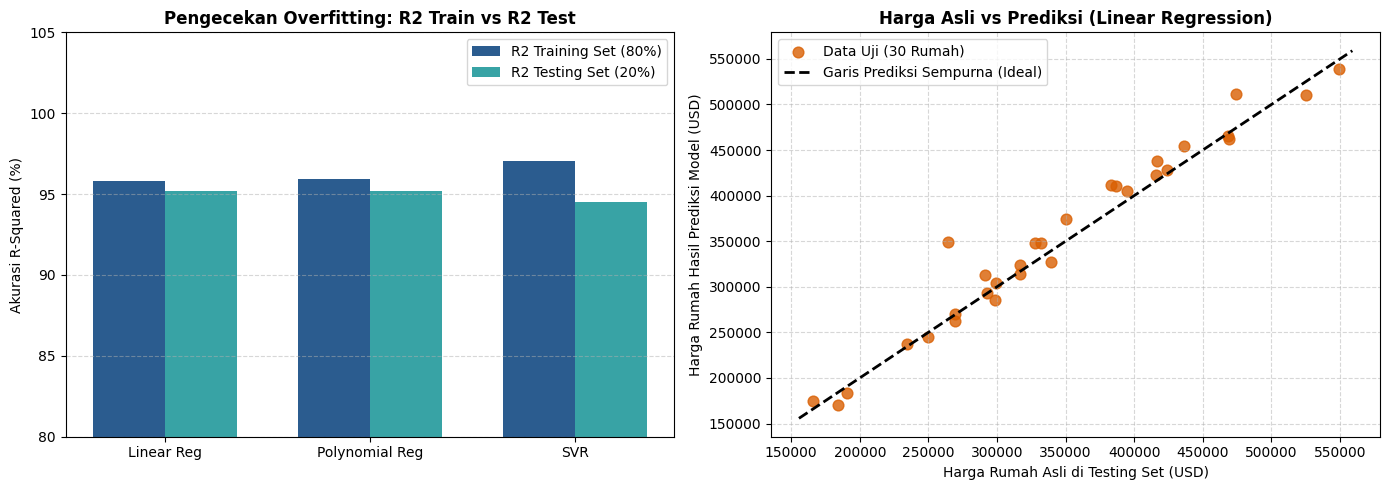


=== HASIL STEP 7: SIMULASI AI INFERENCE (PREDIKSI DATA RUMAH BARU) ===


,Skenario Rumah,Size_sqft,Bedrooms,Location,Prediksi_Harga_USD
0,"Rumah Baru 1 (Contoh Slide Ibu Taniza: City B,...",2000.0,3.0,City B,"$328,427.00"
1,Rumah Baru 2 (Tipe Keluarga Besar di Pusat Kot...,3100.0,5.0,City A,"$521,391.59"
2,Rumah Baru 3 (Tipe Minimalis di Area Pedesaan ...,1100.0,2.0,City C,"$172,228.94"


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

daftar_model = {
    'Linear Regression': model_linear,
    'Polynomial Regression (Deg 2)': model_poly,
    'Support Vector Regression (SVR)': model_svr
}

hasil_evaluasi = []

for nama_model, model in daftar_model.items():
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    mae_test = mean_absolute_error(y_test, pred_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))
    r2_train = r2_score(y_train, pred_train)
    r2_test = r2_score(y_test, pred_test)
    selisih_r2 = abs(r2_train - r2_test)

    if r2_test < 0.70:
        status = "Underfitting"
    elif selisih_r2 > 0.10:
        status = "Indikasi Overfitting"
    else:
        status = "Good Fit (Optimal & Stabil)"

    hasil_evaluasi.append({
        'Algoritma Model': nama_model,
        'MAE Test (USD)': round(mae_test, 2),
        'RMSE Test (USD)': round(rmse_test, 2),
        'R2 Train (%)': round(r2_train * 100, 2),
        'R2 Test (%)': round(r2_test * 100, 2),
        'Selisih Train-Test (%)': round(selisih_r2 * 100, 2),
        'Status Model': status
    })

df_evaluasi = pd.DataFrame(hasil_evaluasi)

print("=== HASIL STEP 6: TABEL EVALUASI PERFORMA KETIGA ALGORITMA REGRESI ===")
display(df_evaluasi)

baris_terbaik = df_evaluasi.loc[df_evaluasi['R2 Test (%)'].idxmax()]
nama_model_terbaik = baris_terbaik['Algoritma Model']
model_terbaik = daftar_model[nama_model_terbaik]
print(f"\nModel Terbaik: {nama_model_terbaik} dengan Akurasi R2 Test = {baris_terbaik['R2 Test (%)']}% dan MAE = ${baris_terbaik['MAE Test (USD)']:,.2f}\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_pos = np.arange(len(df_evaluasi))
lebar = 0.35
axes[0].bar(x_pos - lebar/2, df_evaluasi['R2 Train (%)'], lebar, label='R2 Training Set (80%)', color='#2b5c8f')
axes[0].bar(x_pos + lebar/2, df_evaluasi['R2 Test (%)'], lebar, label='R2 Testing Set (20%)', color='#38a3a5')
axes[0].set_title('Pengecekan Overfitting: R2 Train vs R2 Test', fontweight='bold')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(['Linear Reg', 'Polynomial Reg', 'SVR'])
axes[0].set_ylabel('Akurasi R-Squared (%)')
axes[0].set_ylim(80, 105)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

y_pred_terbaik = model_terbaik.predict(X_test)
axes[1].scatter(y_test, y_pred_terbaik, color='#d95f02', s=60, alpha=0.8, label='Data Uji (30 Rumah)')
batas_min, batas_max = y_test.min() - 10000, y_test.max() + 10000
axes[1].plot([batas_min, batas_max], [batas_min, batas_max], 'k--', lw=2, label='Garis Prediksi Sempurna (Ideal)')
axes[1].set_title(f'Harga Asli vs Prediksi ({nama_model_terbaik})', fontweight='bold')
axes[1].set_xlabel('Harga Rumah Asli di Testing Set (USD)')
axes[1].set_ylabel('Harga Rumah Hasil Prediksi Model (USD)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("=== HASIL STEP 7: SIMULASI AI INFERENCE (PREDIKSI DATA RUMAH BARU) ===")
print("=" * 70)

data_rumah_baru = pd.DataFrame({
    'Skenario Rumah': [
        'Rumah Baru 1 (Contoh Slide Ibu Taniza: City B, 3 Kamar)',
        'Rumah Baru 2 (Tipe Keluarga Besar di Pusat Kota / City A)',
        'Rumah Baru 3 (Tipe Minimalis di Area Pedesaan / City C)'
    ],
    'Size_sqft': [2000.0, 3100.0, 1100.0],
    'Bedrooms': [3.0, 5.0, 2.0],
    'Location': ['City B', 'City A', 'City C']
})

mapping_lokasi = {'City C': 1, 'City B': 2, 'City A': 3}
data_rumah_baru['Location_Encoded'] = data_rumah_baru['Location'].map(mapping_lokasi)

fitur_input_baru = data_rumah_baru[['Size_sqft', 'Bedrooms', 'Location_Encoded']]
prediksi_harga_baru = model_terbaik.predict(fitur_input_baru)

data_rumah_baru['Prediksi_Harga_USD'] = [f"${harga:,.2f}" for harga in prediksi_harga_baru]

display(data_rumah_baru[['Skenario Rumah', 'Size_sqft', 'Bedrooms', 'Location', 'Prediksi_Harga_USD']])